# Delivery Delay Analysis — Detailed Notebook
**Course:** Data Analysis (Set A) · Red & White Skill Education

**Business objective:** determine which delivery **service type** carries the greatest cumulative delay, which **hub** needs priority attention, and what management should do first.

**Questions answered**
1. Which service type has the largest total `delay_days`?
2. Which hub has the largest total `delay_days`?
3. How does the delay burden change Jan → Mar?
4. What share of deliveries were delayed?
5. Which routes contribute most?
6. What should management prioritise?

> **Interpretation rule:** each row is a *month-end route/hub summary*, not a parcel. `delay_days` is a **cumulative record-level delay burden**, not "parcels to expedite today".

**Contents**: 1 Setup · 2 Load · 3 Validation · 4 Cleaning · 5 Merge · 6 Metrics · 7 Summaries · 8 Visuals · 9 Burden vs incidence · 10 Sensitivity · 11 SQL cross-check · 12 Reconciliation · 13 Findings · 14 Limitations

## 1. Setup
The notebook finds the repository root (the folder containing `data/raw/`) so it works from the repo root or from `notebooks/`.

In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def find_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "data" / "raw" / "deliveries.csv").exists():
            return p
    raise FileNotFoundError("Run from inside the repository (data/raw/deliveries.csv not found).")

ROOT = find_root()
RAW = ROOT / "data" / "raw"
MONTH_ORDER = ["Jan", "Feb", "Mar"]
print("Repo root :", ROOT.name)
print("pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

Repo root : delivery-delay-analysis
pandas 3.0.2 | matplotlib 3.10.8


## 2. Load the raw data
Both files are read exactly as supplied (UTF-8). Raw files are never modified.

In [2]:
deliveries_raw = pd.read_csv(RAW / "deliveries.csv", encoding="utf-8")
routes = pd.read_csv(RAW / "routes.csv", encoding="utf-8")
print("deliveries.csv shape:", deliveries_raw.shape)
display(deliveries_raw)
print("routes.csv shape:", routes.shape)
display(routes)

deliveries.csv shape: (13, 6)


,record_id,month,route_id,hub,promised_days,actual_days
0,1,Jan,R1,Mumbai,2,2
1,2,Jan,R2,Chennai,3,4
2,3,Jan,R3,Delhi,5,8
3,4,Jan,R4,Mumbai,6,10
4,5,Feb,R1,Chennai,2,5
5,6,Feb,R2,Delhi,3,3
6,7,Feb,R3,Delhi,5,10
7,8,Feb,R4,Chennai,6,7
8,9,Mar,R1,Delhi,2,8
9,10,Mar,R2,Mumbai,3,5


routes.csv shape: (4, 3)


,route_id,route,service_type
0,R1,Metro Link,Express
1,R2,City Dash,Express
2,R3,Highway Freight,Standard
3,R4,Rural Feeder,Standard


## 3. Validation of the raw inputs
Row counts alone are not enough, so we also check columns, data types, missing values, key uniqueness and the duplicate count. Any failure raises an error rather than being silently ignored.

In [3]:
checks = {}
checks["deliveries columns correct"] = list(deliveries_raw.columns) == ["record_id","month","route_id","hub","promised_days","actual_days"]
checks["routes columns correct"]     = list(routes.columns) == ["route_id","route","service_type"]
checks["13 raw delivery rows"]       = len(deliveries_raw) == 13
checks["4 route rows"]               = len(routes) == 4
checks["record_id is integer"]       = pd.api.types.is_integer_dtype(deliveries_raw["record_id"])
checks["promised/actual numeric"]    = all(pd.api.types.is_numeric_dtype(deliveries_raw[c]) for c in ["promised_days","actual_days"])
checks["text columns are text"]      = all((deliveries_raw[c].map(type) == str).all() for c in ["month","route_id","hub"])
checks["no missing values"]          = not (deliveries_raw.isna().any().any() or routes.isna().any().any())
checks["route_id unique in lookup"]  = routes["route_id"].is_unique
checks["months in Jan/Feb/Mar"]      = set(deliveries_raw["month"]) <= set(MONTH_ORDER)
checks["exactly 1 exact duplicate"]  = int(deliveries_raw.duplicated().sum()) == 1

report = pd.DataFrame({"check": checks.keys(), "passed": checks.values()})
display(report)
assert all(checks.values()), "A raw-data validation check failed"
print("All raw-data validation checks passed.")
display(deliveries_raw.dtypes.to_frame("dtype"))

,check,passed
0,deliveries columns correct,True
1,routes columns correct,True
2,13 raw delivery rows,True
3,4 route rows,True
4,record_id is integer,True
5,promised/actual numeric,True
6,text columns are text,True
7,no missing values,True
8,route_id unique in lookup,True
9,months in Jan/Feb/Mar,True


All raw-data validation checks passed.


,dtype
record_id,int64
month,str
route_id,str
hub,str
promised_days,int64
actual_days,int64


## 4. Cleaning — remove the exact duplicate
`record_id = 12` appears twice with identical values. We keep the first occurrence and keep every other record untouched. No values are imputed or edited.

In [4]:
dup_rows = deliveries_raw[deliveries_raw.duplicated(keep=False)]
print("Rows involved in the duplicate:")
display(dup_rows)

deliveries = deliveries_raw.drop_duplicates(keep="first").reset_index(drop=True)
assert len(deliveries) == 12 and deliveries["record_id"].is_unique
print(f"Rows before: {len(deliveries_raw)}  ->  after: {len(deliveries)}  (removed {len(deliveries_raw)-len(deliveries)})")

Rows involved in the duplicate:


,record_id,month,route_id,hub,promised_days,actual_days
11,12,Mar,R4,Mumbai,6,15
12,12,Mar,R4,Mumbai,6,15


Rows before: 13  ->  after: 12  (removed 1)


## 5. Merge the route lookup
Relationship is **one-to-many**: one route → many delivery records. `validate="many_to_one"` makes pandas fail if `routes.route_id` were not unique. A left join keeps all 12 deliveries, then we assert there are no unmatched keys.

In [5]:
df = deliveries.merge(routes, on="route_id", how="left", validate="many_to_one")
assert len(df) == 12
assert df["service_type"].notna().all(), "Unmatched route_id after merge"
print("Unmatched route keys:", int(df["service_type"].isna().sum()))
display(df.head())

Unmatched route keys: 0


,record_id,month,route_id,hub,promised_days,actual_days,route,service_type
0,1,Jan,R1,Mumbai,2,2,Metro Link,Express
1,2,Jan,R2,Chennai,3,4,City Dash,Express
2,3,Jan,R3,Delhi,5,8,Highway Freight,Standard
3,4,Jan,R4,Mumbai,6,10,Rural Feeder,Standard
4,5,Feb,R1,Chennai,2,5,Metro Link,Express


## 6. Business metrics
```text
delay_days           = MAX(actual_days - promised_days, 0)
Delayed record       = actual_days > promised_days
Delay incidence rate = delayed records / total records * 100
```
Early or on-time deliveries give **0** (never negative). Month is an *ordered categorical* so everything sorts Jan → Feb → Mar, not alphabetically.

In [6]:
df["delay_days"]  = (df["actual_days"] - df["promised_days"]).clip(lower=0)
df["is_delayed"]  = df["actual_days"] > df["promised_days"]
df["month"]       = pd.Categorical(df["month"], categories=MONTH_ORDER, ordered=True)
assert df["delay_days"].ge(0).all()

# Spec worked examples
ex = df.set_index("record_id")
assert (ex.loc[1,"delay_days"], ex.loc[2,"delay_days"], ex.loc[3,"delay_days"], ex.loc[12,"delay_days"]) == (0,1,3,9)
print("Worked examples from the specification verified (0, 1, 3, 9).")
display(df[["record_id","month","route_id","route","hub","service_type","promised_days","actual_days","delay_days","is_delayed"]])

Worked examples from the specification verified (0, 1, 3, 9).


,record_id,month,route_id,route,hub,service_type,promised_days,actual_days,delay_days,is_delayed
0,1,Jan,R1,Metro Link,Mumbai,Express,2,2,0,False
1,2,Jan,R2,City Dash,Chennai,Express,3,4,1,True
2,3,Jan,R3,Highway Freight,Delhi,Standard,5,8,3,True
3,4,Jan,R4,Rural Feeder,Mumbai,Standard,6,10,4,True
4,5,Feb,R1,Metro Link,Chennai,Express,2,5,3,True
5,6,Feb,R2,City Dash,Delhi,Express,3,3,0,False
6,7,Feb,R3,Highway Freight,Delhi,Standard,5,10,5,True
7,8,Feb,R4,Rural Feeder,Chennai,Standard,6,7,1,True
8,9,Mar,R1,Metro Link,Delhi,Express,2,8,6,True
9,10,Mar,R2,City Dash,Mumbai,Express,3,5,2,True


In [7]:
n = len(df); delayed = int(df["is_delayed"].sum()); total_delay = df["delay_days"].sum()
overall = {"delivery_count": n, "delayed_count": delayed, "total_delay_days": total_delay,
           "delay_incidence_rate_%": round(delayed / n * 100, 2)}
overall

{'delivery_count': 12,
 'delayed_count': 9,
 'total_delay_days': np.int64(34),
 'delay_incidence_rate_%': 75.0}

## 7. Summaries by service type, hub, route and month
Every rate is computed from **underlying counts** (`delayed_count / delivery_count`). Averaging subgroup percentages is wrong when group sizes differ.

In [8]:
def summarise(data, keys):
    out = (data.groupby(keys, observed=True, sort=False)
               .agg(delivery_count=("record_id","count"),
                    delayed_count=("is_delayed","sum"),
                    total_delay_days=("delay_days","sum"))
               .reset_index())
    out["delayed_count"] = out["delayed_count"].astype(int)
    out["delay_incidence_rate_%"] = (out["delayed_count"] / out["delivery_count"] * 100).round(2)
    out["share_of_total_delay_%"] = (out["total_delay_days"] / data["delay_days"].sum() * 100).round(2)
    return out

service = summarise(df, ["service_type"]).sort_values(["total_delay_days","service_type"], ascending=[False,True]).reset_index(drop=True)
hub     = summarise(df, ["hub"]).sort_values(["total_delay_days","hub"], ascending=[False,True]).reset_index(drop=True)
route   = summarise(df, ["route_id","route","service_type"]).sort_values(["total_delay_days","route_id"], ascending=[False,True]).reset_index(drop=True)
monthly = summarise(df, ["month"]).sort_values("month").reset_index(drop=True)
monthly["month"] = monthly["month"].astype(str)
monthly["change_vs_prev_month"] = monthly["total_delay_days"].diff()

for name, t in [("Service type", service), ("Hub", hub), ("Route", route), ("Month", monthly)]:
    print(f"\n=== {name} ===")
    display(t)

for t in (service, hub, route, monthly):          # every grouping must reconcile to the same total
    assert t["total_delay_days"].sum() == total_delay and t["delivery_count"].sum() == 12
print("\nAll four summaries sum to", total_delay, "delay days over 12 records.")


=== Service type ===


,service_type,delivery_count,delayed_count,total_delay_days,delay_incidence_rate_%,share_of_total_delay_%
0,Standard,6,5,22,83.33,64.71
1,Express,6,4,12,66.67,35.29



=== Hub ===


,hub,delivery_count,delayed_count,total_delay_days,delay_incidence_rate_%,share_of_total_delay_%
0,Mumbai,4,3,15,75.0,44.12
1,Delhi,4,3,14,75.0,41.18
2,Chennai,4,3,5,75.0,14.71



=== Route ===


,route_id,route,service_type,delivery_count,delayed_count,total_delay_days,delay_incidence_rate_%,share_of_total_delay_%
0,R4,Rural Feeder,Standard,3,3,14,100.00,41.18
1,R1,Metro Link,Express,3,2,9,66.67,26.47
2,R3,Highway Freight,Standard,3,2,8,66.67,23.53
3,R2,City Dash,Express,3,2,3,66.67,8.82



=== Month ===


,month,delivery_count,delayed_count,total_delay_days,delay_incidence_rate_%,share_of_total_delay_%,change_vs_prev_month
0,Jan,4,3,8,75.0,23.53,NaN
1,Feb,4,3,9,75.0,26.47,1.0
2,Mar,4,3,17,75.0,50.00,8.0



All four summaries sum to 34 delay days over 12 records.


### 7.1 Service-type × month grid (the PivotTable layout)

In [9]:
grid = (df.pivot_table(index="service_type", columns="month", values="delay_days", aggfunc="sum", observed=False, margins=True, margins_name="Grand Total"))
grid

month,Jan,Feb,Mar,Grand Total
service_type,,,,
Express,1,3,8,12
Standard,7,6,9,22
Grand Total,8,9,17,34


### 7.2 Routes above the 8-day threshold
The rule is **strictly greater than 8** (matches SQL query S2b with `HAVING ... > 8`).

In [10]:
over = route[route["total_delay_days"] > 8][["route_id","route","service_type","total_delay_days"]]
display(over)
print("R3 total =", int(route.loc[route.route_id=="R3","total_delay_days"].iloc[0]), "-> exactly 8, so it is NOT included.")

,route_id,route,service_type,total_delay_days
0,R4,Rural Feeder,Standard,14
1,R1,Metro Link,Express,9


R3 total = 8 -> exactly 8, so it is NOT included.


## 8. Visualisations

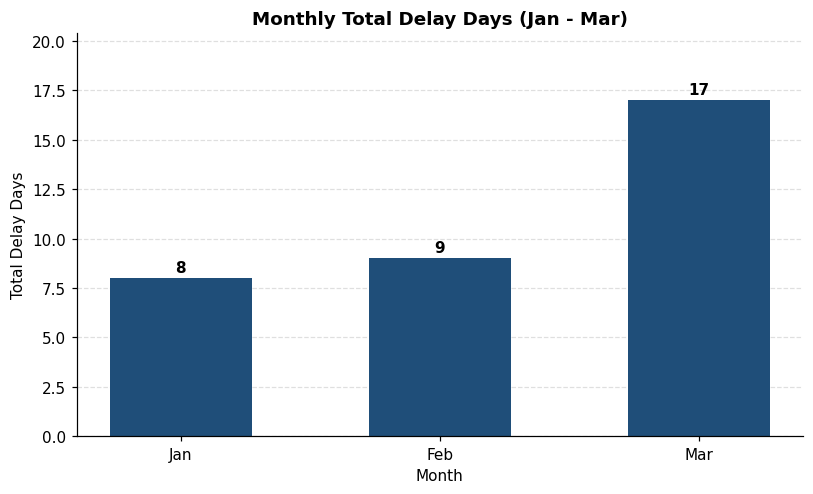

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
bars = ax.bar(monthly["month"], monthly["total_delay_days"], color="#1F4E79", width=0.55)
ax.set_title("Monthly Total Delay Days (Jan - Mar)", fontweight="bold")
ax.set_xlabel("Month"); ax.set_ylabel("Total Delay Days"); ax.set_ylim(0, monthly["total_delay_days"].max()*1.2)
ax.grid(axis="y", ls="--", alpha=.4); ax.set_axisbelow(True)
for b, v in zip(bars, monthly["total_delay_days"]): ax.text(b.get_x()+b.get_width()/2, v+.3, f"{v:g}", ha="center", fontweight="bold")
plt.tight_layout(); plt.show()

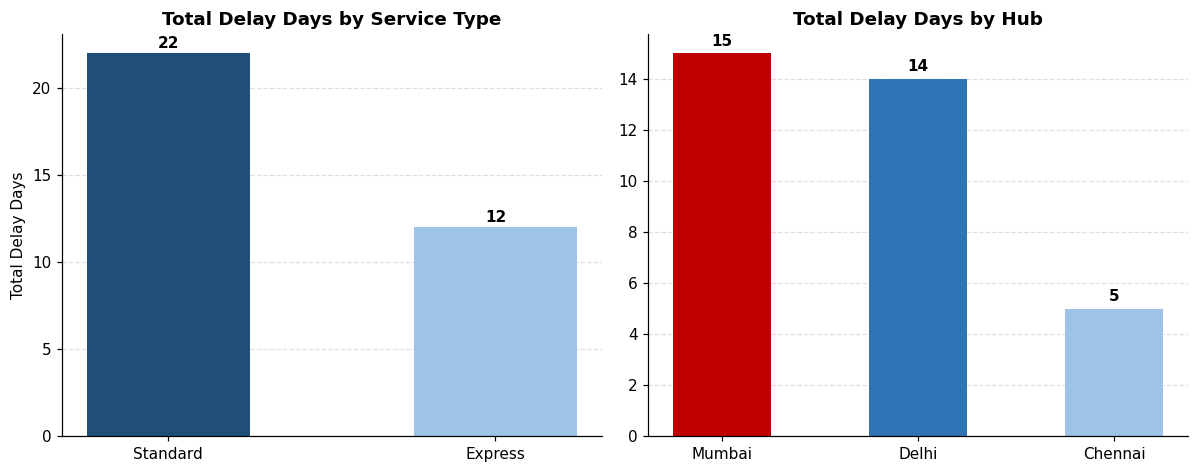

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
colors = ["#1F4E79", "#9DC3E6"]
axes[0].bar(service["service_type"], service["total_delay_days"], color=colors, width=.5)
axes[0].set_title("Total Delay Days by Service Type", fontweight="bold"); axes[0].set_ylabel("Total Delay Days")
for i, v in enumerate(service["total_delay_days"]): axes[0].text(i, v+.3, f"{v:g}", ha="center", fontweight="bold")
axes[1].bar(hub["hub"], hub["total_delay_days"], color=["#C00000","#2E75B6","#9DC3E6"], width=.5)
axes[1].set_title("Total Delay Days by Hub", fontweight="bold")
for i, v in enumerate(hub["total_delay_days"]): axes[1].text(i, v+.3, f"{v:g}", ha="center", fontweight="bold")
for a in axes: a.grid(axis="y", ls="--", alpha=.4); a.set_axisbelow(True)
plt.tight_layout(); plt.show()

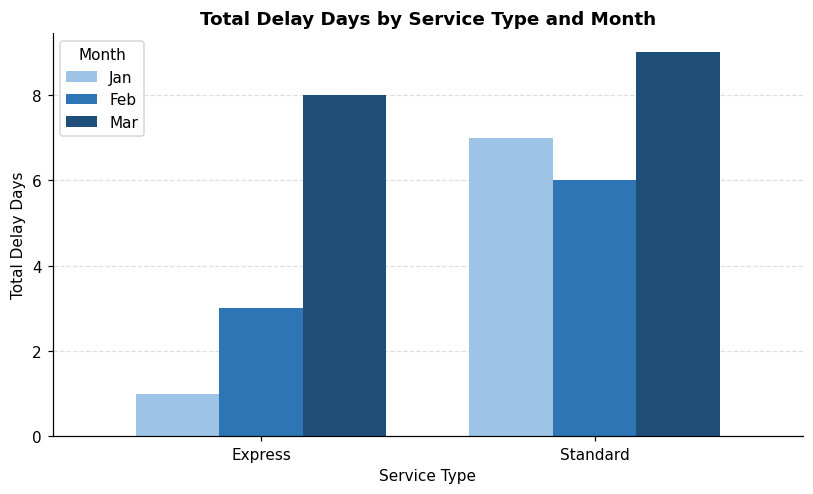

In [13]:
g = grid.drop(index="Grand Total", columns="Grand Total")
ax = g.plot(kind="bar", figsize=(7.5, 4.6), color=["#9DC3E6","#2E75B6","#1F4E79"], rot=0, width=.75)
ax.set_title("Total Delay Days by Service Type and Month", fontweight="bold")
ax.set_xlabel("Service Type"); ax.set_ylabel("Total Delay Days"); ax.legend(title="Month")
ax.grid(axis="y", ls="--", alpha=.4); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

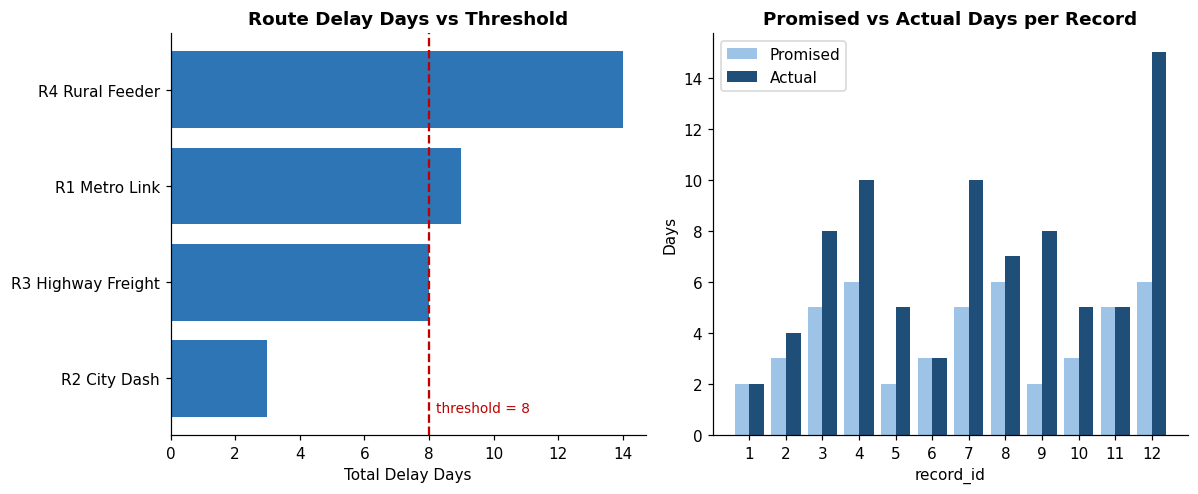

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
r = route.sort_values("total_delay_days")
axes[0].barh(r["route_id"] + " " + r["route"], r["total_delay_days"], color="#2E75B6")
axes[0].axvline(8, color="#C00000", ls="--"); axes[0].text(8.2, -.35, "threshold = 8", color="#C00000", fontsize=9)
axes[0].set_title("Route Delay Days vs Threshold", fontweight="bold"); axes[0].set_xlabel("Total Delay Days")
x = range(len(df))
axes[1].bar([i-.2 for i in x], df["promised_days"], width=.4, label="Promised", color="#9DC3E6")
axes[1].bar([i+.2 for i in x], df["actual_days"], width=.4, label="Actual", color="#1F4E79")
axes[1].set_xticks(list(x)); axes[1].set_xticklabels(df["record_id"])
axes[1].set_title("Promised vs Actual Days per Record", fontweight="bold"); axes[1].set_xlabel("record_id"); axes[1].set_ylabel("Days"); axes[1].legend()
plt.tight_layout(); plt.show()

## 9. Cumulative burden vs delay incidence
These are **different questions**. Burden = *how many delay days accumulate*; incidence = *how often a record is delayed*. A group can have lower burden but still a high incidence.

In [15]:
cmp = service[["service_type","total_delay_days","delivery_count","delayed_count","delay_incidence_rate_%"]].copy()
cmp["avg_delay_days_per_delayed_record"] = (df[df.is_delayed].groupby("service_type")["delay_days"].mean().reindex(cmp["service_type"]).round(2).values)
display(cmp)
display(hub[["hub","total_delay_days","delay_incidence_rate_%"]])

# Why subgroup rates must not be averaged: demonstrate with an unbalanced example
demo = pd.DataFrame({"g": ["A"]*4 + ["B"], "delayed": [1,1,1,1,0]})
rates = demo.groupby("g")["delayed"].mean()*100
print(f"Subgroup rates: {rates.to_dict()} -> average of rates = {rates.mean():.1f}%  but true overall = {demo.delayed.mean()*100:.1f}%")
print("In THIS dataset groups are equal-sized, but the count-based formula is used everywhere so it stays correct if data changes.")

,service_type,total_delay_days,delivery_count,delayed_count,delay_incidence_rate_%,avg_delay_days_per_delayed_record
0,Standard,22,6,5,83.33,4.4
1,Express,12,6,4,66.67,3.0


,hub,total_delay_days,delay_incidence_rate_%
0,Mumbai,15,75.0
1,Delhi,14,75.0
2,Chennai,5,75.0


Subgroup rates: {'A': 100.0, 'B': 0.0} -> average of rates = 50.0%  but true overall = 80.0%
In THIS dataset groups are equal-sized, but the count-based formula is used everywhere so it stays correct if data changes.


## 10. Sensitivity — how fragile is the hub ranking?
Rows are month-end summaries and a hub × route cell holds only 1–2 records, so a single record can drive a ranking. We test the hub ranking with each record removed in turn (leave-one-out).

In [16]:
rows = []
for rid in df["record_id"]:
    sub = df[df.record_id != rid].groupby("hub")["delay_days"].sum().sort_values(ascending=False)
    rows.append({"removed_record": rid, "top_hub": sub.index[0], "top_hub_days": sub.iloc[0], "second_hub": sub.index[1], "second_days": sub.iloc[1]})
loo = pd.DataFrame(rows)
display(loo)
flip = loo[loo.top_hub != "Mumbai"]
print("Records whose removal changes the top hub:", flip["removed_record"].tolist())
m_wo = df[(df.hub=="Mumbai") & (df.record_id!=12)]["delay_days"].sum()
print(f"Mumbai delay without record 12 (9 days) = {m_wo:g} vs Delhi = {df[df.hub=='Delhi']['delay_days'].sum():g}")

,removed_record,top_hub,top_hub_days,second_hub,second_days
0,1,Mumbai,15,Delhi,14
1,2,Mumbai,15,Delhi,14
2,3,Mumbai,15,Delhi,11
3,4,Delhi,14,Mumbai,11
4,5,Mumbai,15,Delhi,14
5,6,Mumbai,15,Delhi,14
6,7,Mumbai,15,Delhi,9
7,8,Mumbai,15,Delhi,14
8,9,Mumbai,15,Delhi,8
9,10,Delhi,14,Mumbai,13


Records whose removal changes the top hub: [4, 10, 12]
Mumbai delay without record 12 (9 days) = 6 vs Delhi = 14


## 11. SQL cross-check (in-memory SQLite)
The project's real SQL (`sql/setup.sql`, `queries.sql`) was executed on MariaDB 10.11.14 (MySQL-compatible). Here the *same logic* is replayed in SQLite so the notebook is self-contained. SQLite's scalar `MAX(a, b)` replaces MySQL's `GREATEST(a, b)`; this is the only syntax difference.

In [17]:
con = sqlite3.connect(":memory:")
routes.to_sql("routes", con, index=False)
deliveries.to_sql("deliveries", con, index=False)      # the 12 clean rows (duplicate excluded)

q_service = '''SELECT r.service_type, SUM(MAX(d.actual_days - d.promised_days, 0)) AS total_delay_days
               FROM deliveries d JOIN routes r ON r.route_id = d.route_id
               GROUP BY r.service_type ORDER BY total_delay_days DESC, r.service_type'''
q_routes  = '''SELECT r.route_id, r.route, SUM(MAX(d.actual_days - d.promised_days, 0)) AS total_delay_days
               FROM deliveries d JOIN routes r ON r.route_id = d.route_id
               GROUP BY r.route_id, r.route HAVING SUM(MAX(d.actual_days - d.promised_days, 0)) > 8
               ORDER BY total_delay_days DESC, r.route_id'''
q_hubs    = '''SELECT hub, SUM(MAX(actual_days - promised_days, 0)) AS total_delay_days
               FROM deliveries GROUP BY hub ORDER BY total_delay_days DESC, hub LIMIT 2'''
q_integ   = '''SELECT COUNT(*) AS rows_checked, SUM(r.route_id IS NULL) AS unmatched_route_keys
               FROM deliveries d LEFT JOIN routes r ON r.route_id = d.route_id'''
sql_service = pd.read_sql(q_service, con); sql_routes = pd.read_sql(q_routes, con)
sql_hubs = pd.read_sql(q_hubs, con); sql_integ = pd.read_sql(q_integ, con)
for t in (sql_service, sql_routes, sql_hubs, sql_integ): display(t)

assert dict(zip(sql_service.service_type, sql_service.total_delay_days)) == dict(zip(service.service_type, service.total_delay_days))
assert sql_routes.route_id.tolist() == over.route_id.tolist()
assert sql_hubs.hub.tolist() == hub.hub.tolist()[:2]
assert int(sql_integ.unmatched_route_keys[0]) == 0
print("SQL results agree with pandas.")

,service_type,total_delay_days
0,Standard,22
1,Express,12


,route_id,route,total_delay_days
0,R4,Rural Feeder,14
1,R1,Metro Link,9


,hub,total_delay_days
0,Mumbai,15
1,Delhi,14


,rows_checked,unmatched_route_keys
0,12,0


SQL results agree with pandas.


## 12. Reconciliation against the validation targets
Targets come from the project specification and are used **only to detect errors** — they are compared with the values calculated above, never used in place of them.

In [18]:
targets = {
    "Total delay days": (34, total_delay),
    "Jan delay": (8,  monthly.set_index("month").loc["Jan","total_delay_days"]),
    "Feb delay": (9,  monthly.set_index("month").loc["Feb","total_delay_days"]),
    "Mar delay": (17, monthly.set_index("month").loc["Mar","total_delay_days"]),
    "Standard delay": (22, service.set_index("service_type").loc["Standard","total_delay_days"]),
    "Express delay":  (12, service.set_index("service_type").loc["Express","total_delay_days"]),
    "Mumbai delay":  (15, hub.set_index("hub").loc["Mumbai","total_delay_days"]),
    "Delhi delay":   (14, hub.set_index("hub").loc["Delhi","total_delay_days"]),
    "Chennai delay": (5,  hub.set_index("hub").loc["Chennai","total_delay_days"]),
    "Clean rows": (12, len(df)),
    "Delayed records": (9, delayed),
    "Overall incidence %": (75.00, overall["delay_incidence_rate_%"]),
    "R4 delay": (14, route.set_index("route_id").loc["R4","total_delay_days"]),
    "R4 share %": (41.18, route.set_index("route_id").loc["R4","share_of_total_delay_%"]),
    "Standard incidence %": (83.33, service.set_index("service_type").loc["Standard","delay_incidence_rate_%"]),
    "Express incidence %": (66.67, service.set_index("service_type").loc["Express","delay_incidence_rate_%"]),
}
rec = pd.DataFrame([{"metric": k, "expected": e, "calculated": float(a), "match": abs(e-float(a)) < 0.005} for k,(e,a) in targets.items()])
display(rec)
assert rec["match"].all(), "A validation target did not match"
assert hub.hub.tolist()[:2] == ["Mumbai","Delhi"] and route.route_id.iloc[0] == "R4"
print("All", len(rec), "validation targets match.")

,metric,expected,calculated,match
0,Total delay days,34.00,34.00,True
1,Jan delay,8.00,8.00,True
2,Feb delay,9.00,9.00,True
3,Mar delay,17.00,17.00,True
4,Standard delay,22.00,22.00,True
5,Express delay,12.00,12.00,True
6,Mumbai delay,15.00,15.00,True
7,Delhi delay,14.00,14.00,True
8,Chennai delay,5.00,5.00,True
9,Clean rows,12.00,12.00,True


All 16 validation targets match.


## 13. Findings and recommendation (generated from the computed results)

In [19]:
from IPython.display import Markdown
top_s, low_s = service.iloc[0], service.iloc[1]
top_h = hub.iloc[0]; r4 = route.iloc[0]
jan, mar = monthly.iloc[0], monthly.iloc[-1]
Markdown(f'''
**Numeric findings**
1. Total cumulative delay is **{total_delay:g} days**; **{delayed} of {n}** records were delayed (**{overall["delay_incidence_rate_%"]:.2f}%**).
2. **{top_s.service_type}** carries the greatest burden: **{top_s.total_delay_days:g} days** ({top_s["share_of_total_delay_%"]:.2f}% of total) vs {low_s.service_type} {low_s.total_delay_days:g}; incidence {top_s["delay_incidence_rate_%"]:.2f}% vs {low_s["delay_incidence_rate_%"]:.2f}%.
3. **{top_h.hub}** is the highest-delay hub with **{top_h.total_delay_days:g} days**, followed by {hub.iloc[1].hub} ({hub.iloc[1].total_delay_days:g}); all hubs share the same incidence ({hub["delay_incidence_rate_%"].iloc[0]:.2f}%), so hub differences are about **severity**, not frequency.
4. Delay rose from **{jan.total_delay_days:g} ({jan.month}) to {mar.total_delay_days:g} ({mar.month})** while delayed-record counts stayed flat, i.e. delays became longer.
5. Route **{r4.route_id} {r4.route}** contributes **{r4.total_delay_days:g} days = {r4["share_of_total_delay_%"]:.2f}%** of all delay.

**Recommendation:** review the Standard route **R4 (Rural Feeder) out of Mumbai** first, then Delhi - promised vs actual commitments and handling steps on that lane (record 12: promised 6, actual 15).

**Evidence:** R4 has the highest route total, is delayed in 3 of 3 records, and Mumbai has the highest hub total - both point to the same lane. However, Mumbai leads Delhi by only {top_h.total_delay_days - hub.iloc[1].total_delay_days:g} day, and removing any one of records {flip['removed_record'].tolist()} changes the top hub (section 10), so treat the hub ranking as fragile and the recommendation as a **priority for investigation**, not a proven cause.
''')


**Numeric findings**
1. Total cumulative delay is **34 days**; **9 of 12** records were delayed (**75.00%**).
2. **Standard** carries the greatest burden: **22 days** (64.71% of total) vs Express 12; incidence 83.33% vs 66.67%.
3. **Mumbai** is the highest-delay hub with **15 days**, followed by Delhi (14); all hubs share the same incidence (75.00%), so hub differences are about **severity**, not frequency.
4. Delay rose from **8 (Jan) to 17 (Mar)** while delayed-record counts stayed flat, i.e. delays became longer.
5. Route **R4 Rural Feeder** contributes **14 days = 41.18%** of all delay.

**Recommendation:** review the Standard route **R4 (Rural Feeder) out of Mumbai** first, then Delhi - promised vs actual commitments and handling steps on that lane (record 12: promised 6, actual 15).

**Evidence:** R4 has the highest route total, is delayed in 3 of 3 records, and Mumbai has the highest hub total - both point to the same lane. However, Mumbai leads Delhi by only 1 day, and removing any one of records [4, 10, 12] changes the top hub (section 10), so treat the hub ranking as fragile and the recommendation as a **priority for investigation**, not a proven cause.


## 14. Limitations
- 12 synthetic summary rows over 3 months; no statistical significance can be claimed.
- Rows are month-end summaries, not parcels; delay days are cumulative and are **not** a count of parcels to expedite.
- No data on volume, capacity, weather or distance → **no causal claim** is made.
- Hub × route cells hold 1-2 records, so single records can drive rankings (section 10).
- Equal group sizes make several incidence rates identical (75%); the count-based formula is still used so results stay correct if the data changes.

**Companion deliverables in the repository:** `python/analysis.py` (script + 19 tests), `sql/` (MySQL-compatible), `excel/analysis.xlsx`, `docs/`. Power BI build guide: `docs/powerbi_guide.md` (PBIX pending).